![Banner](../images/03_regression_kriging.png)

# Regression Kriging



Regression kriging predicts a value at a place you did not sample by adding two surfaces. The first is a regression on covariates that are known at the samples and at the target: a digital elevation model, NDVI, rainfall, soil texture, a land-cover class. The second is ordinary kriging of the residuals that regression left behind. The covariates carry the broad pattern. The residual kriging carries the local pattern the covariates missed, and it returns a standard error for that residual.

This notebook is the map for regression kriging in GeoLattice. It writes the two-step predictor, places it beside universal kriging and kriging with an external drift, and runs the sum on eight points through `geolattice.geostatistics.RegressionKriging`. The five notebooks that follow keep this estimator and change the trend model, on the Great Plains soil organic carbon survey.

Six notebooks add a regression trend to ordinary kriging of the residuals. The five hands-on notebooks map soil organic carbon on the Great Plains, using NDVI, rainfall, temperature, elevation, slope, topographic position, aspect, the K-factor, silt plus clay, and land cover.

- **Regression Kriging.** This notebook. The two-step sum on eight points, with NDVI as the covariate and a known spherical residual variogram.
- **Regression Kriging with scikit-Learn.** Linear models, trees, a GAM, a GLM, and quantile regression, with cross-validation and a prediction grid.
- **Regression Kriging with H2O.** The same survey, with AutoML, GLM, gradient boosting, and random forest fitting the trend.
- **Regression Kriging with PyTorch.** A multilayer-perceptron trend, with an optional hyperparameter search.
- **Regression Kriging with TensorFlow.** The same deep trend on the TensorFlow and Keras stack.
- **Regression Kriging with Graph Neural Networks.** The trend is learned on a neighbourhood graph, with `GNNRegressionKriging`, `KCN`, and `IGNNK`.

Library: `geolattice.geostatistics`


**Worked example:** eight samples and one target. NDVI is the covariate. The residual variogram is a known spherical model.

**Library:** `geolattice.geostatistics`,  class `RegressionKriging`

**Before this notebook:** [Getting started](../05_01_foundation/05_00_getting_started.ipynb), [variogram modeling](../05_01_foundation/05_01_variogram_modeling.ipynb), and [introduction to kriging](../05_02_kriging/05_02_00_introduction_kriging.ipynb). Regression kriging calls ordinary kriging on residuals. The variogram and the ordinary-kriging system are assumed from those notebooks.

The five notebooks that follow apply the same two-step sum to Great Plains soil organic carbon, with a different trend model in each.



## Table of Contents

- [What this chapter covers](#what-this-chapter-covers)
1. [Notebooks in this chapter](#1-notebooks-in-this-chapter)
2. [What regression kriging is](#2-what-regression-kriging-is)
3. [How regression kriging works](#how-regression-kriging-works)
    - 3.1 [Fit the trend](#fit-the-trend)
    - 3.2 [Form the residuals and their variogram](#form-the-residuals-and-their-variogram)
    - 3.3 [Ordinary-krige the residuals](#ordinary-krige-the-residuals)
    - 3.4 [Add the two surfaces](#add-the-two-surfaces)
4. [Universal kriging and external drift](#universal-kriging-and-external-drift)
5. [Regression kriging in GeoLattice](#regression-kriging-in-geolattice)
    - 5.1 [Trend models on the scikit-learn path](#trend-models-on-the-scikit-learn-path)
    - 5.2 [The same sum, with a different trend engine](#the-same-sum-with-a-different-trend-engine)
6. [Python setup](#python-setup)
7. [An eight-point regression-kriging sum](#an-eight-point-regression-kriging-sum)
8. [Where the next notebooks go](#where-the-next-notebooks-go)
9. [Resources](#resources)
    - 9.1 [Textbooks and reviews](#textbooks-and-reviews)
    - 9.2 [In this library](#in-this-library)



## Overview

Write the quantity of interest as

$$
Z(\mathbf{x}) = m(\mathbf{x}) + \varepsilon(\mathbf{x}).
$$

$m(\mathbf{x})$ is a trend that depends on covariates $\mathbf{q}(\mathbf{x})$: NDVI, elevation, mean annual precipitation, a land-cover class. $\varepsilon(\mathbf{x})$ is a zero-mean residual field with a variogram. At an unsampled location $\mathbf{x}_0$ the regression-kriging predictor is

$$
\hat Z(\mathbf{x}_0)
  = \hat m(\mathbf{x}_0)
  + \sum_{i=1}^{n} \lambda_i \, e(\mathbf{x}_i),
\qquad
e(\mathbf{x}_i) = Z(\mathbf{x}_i) - \hat m(\mathbf{x}_i).
$$

$\hat m(\mathbf{x}_0)$ is the fitted regression evaluated at the target's covariates. The sum is ordinary kriging of the residuals, with weights $\lambda_i$ from the residual variogram. The two pieces are added. That is the whole estimator.

Three names in the literature refer to this decomposition, with one difference in the kriging step:

| Name | Where it comes from | Residual predictor in the usual statement |
|---|---|---|
| **Regression kriging** | Soil and environmental mapping (Odeh, McBratney & Chittleborough, 1995; Hengl, Heuvelink & Stein, 2004) | Ordinary kriging of residuals |
| **Simple kriging with a varying local mean** | The geostatistical literature (Goovaerts, 1997) | Simple kriging, with the regression surface treated as a known mean |
| **Residual kriging** | The same two-step sum, named for the second step | Ordinary or simple kriging of residuals |

GeoLattice implements the ordinary-kriging form. `RegressionKriging` accepts `kriging_type="ordinary"` only. For ordinary least squares with an intercept, the sample mean of the residuals is zero, so simple kriging with mean 0 and ordinary kriging of those residuals are close. Ordinary kriging spends one constraint, $\sum \lambda_i = 1$, on that mean.

The covariates have to be known at $\mathbf{x}_0$. A digital elevation model, a satellite grid, or a climate surface supplies them: dense everywhere, while the soil or water samples are sparse.


---

## How regression kriging works

The fit is three steps. The predict step adds the first and the third back together.

### Fit the trend

On the $n$ samples, fit any model

$$
\hat m(\mathbf{x}_i) = f\bigl(\mathbf{q}(\mathbf{x}_i)\bigr).
$$

For a linear trend this is ordinary least squares,

$$
\hat{\boldsymbol{\beta}} = (\mathbf{Q}^{\top}\mathbf{Q})^{-1}\mathbf{Q}^{\top}\mathbf{z},
\qquad
\hat m(\mathbf{x}_i) = \mathbf{q}_i^{\top}\hat{\boldsymbol{\beta}},
$$

with a column of ones in $\mathbf{Q}$ when the model has an intercept. A random forest, a generalized additive model, a gradient-boosted tree, or a neural net replaces that closed form with its own $f$. The kriging step does not need to know which one it was. It only needs the residuals.

### Form the residuals and their variogram

$$
e(\mathbf{x}_i) = Z(\mathbf{x}_i) - \hat m(\mathbf{x}_i).
$$

The experimental semivariogram of these residuals is the same average as in the variogram notebook,

$$
\hat\gamma_e(h) = \frac{1}{2N(h)}\sum_{(i,j)}\bigl(e(\mathbf{x}_i)-e(\mathbf{x}_j)\bigr)^2,
$$

and kriging evaluates a fitted authorized model of $\gamma_e$, not the experimental points. Under second-order stationarity of the residual,

$$
C_e(h) = C_e(0) - \gamma_e(h), \qquad C_e(0) = c_0 + c.
$$

Fit this variogram on the training residuals. A variogram that has seen the test residuals makes the later validation optimistic. A regression that has captured the broad pattern leaves a residual sill well below the sill of $Z$. That smaller sill is the variance the kriging standard error can still report.

### Ordinary-krige the residuals

This is the ordinary-kriging system from the [kriging introduction](../05_02_kriging/05_02_00_introduction_kriging.ipynb), with $C_e$ in place of the covariance of $Z$:

$$
\begin{bmatrix}
\mathbf{C}_e & \mathbf{1} \\
\mathbf{1}^{\top} & 0
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda} \\
\mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_e \\
1
\end{bmatrix}.
$$

$\mathbf{C}_e$ holds residual covariances among the samples, $\mathbf{c}_e$ holds residual covariances between the samples and the target, and $\mu$ is the Lagrange multiplier for $\sum\lambda_i = 1$. Then

$$
\hat e(\mathbf{x}_0) = \boldsymbol{\lambda}^{\top}\mathbf{e},
\qquad
\sigma_e(\mathbf{x}_0) = \sqrt{C_e(0) - \boldsymbol{\lambda}^{\top}\mathbf{c}_e - \mu}.
$$

Distance, declustering, and screening act on the residuals exactly as they act on $Z$ in ordinary kriging. A sample with a large $C_e(\mathbf{x}_i-\mathbf{x}_0)$ takes a large weight. Two samples that sit on top of each other split one weight. A sample hidden behind a closer one can take a small negative weight.

### Add the two surfaces

$$
\hat Z(\mathbf{x}_0) = \hat m(\mathbf{x}_0) + \hat e(\mathbf{x}_0).
$$

Read the two terms as different kinds of information.

- **The regression term** can move $\hat Z(\mathbf{x}_0)$ far from the neighbouring sample values, when the target's covariates are unlike the covariates of those neighbours. A pixel with high NDVI is predicted high even if the nearest soil pits were in sparse vegetation, provided some pits somewhere in the sample span that high NDVI.
- **The residual term** is a local correction in the units of $Z$. Far from every sample, ordinary kriging of a zero-mean residual returns about zero, and $\hat Z$ falls back to the regression surface. Beside a sample, $\hat e$ removes the local miss of that surface.

`RegressionKriging.predict(..., return_std=True)` returns $\sigma_e(\mathbf{x}_0)$, the residual kriging standard error, in the units of $Z$. It is small where samples are dense relative to the residual range, and it grows toward $\sqrt{C_e(0)}$ in empty parts of the domain. Uncertainty in $\hat{\boldsymbol{\beta}}$, or in a fitted forest, is a separate number. The kriging standard error does not include it. A Bayesian ridge trend can report its own predictive standard deviation through `rk.regressor.predict(X, return_std=True)`. Keep that figure beside $\sigma_e$, rather than treating $\sigma_e$ as a full interval for $Z$.


---

## Universal kriging and external drift

Universal kriging, kriging with an external drift, and regression kriging all write $Z = m + \varepsilon$. They differ in what $m$ is allowed to depend on, and in whether the coefficients of $m$ are estimated inside the kriging system or before it.

| | Universal kriging | Kriging with an external drift | Regression kriging |
|---|---|---|---|
| Trend | A polynomial of the coordinates | A linear function of external covariates | Any regression on external covariates |
| Where the coefficients are estimated | Inside the kriging system | Inside the kriging system | First, by the regression; then the residuals are kriged |
| What has to be known at $\mathbf{x}_0$ | The coordinates, which you always have | The covariates | The covariates |
| Variogram | Of the residuals of the polynomial | Of the residuals of the drift | Of the residuals of the regression |
| A random forest, GAM, or neural net | No polynomial column carries those fits | No drift column carries those fits | The residual kriging is unchanged |

Universal kriging is the case already in [05_02_03_universal_kriging.ipynb](../05_02_kriging/05_02_03_universal_kriging.ipynb): $m$ is $1$, $x$, $y$, and higher powers, and the weights reproduce each basis function at the target. A hill, a climate gradient, or a vegetation index that is not a polynomial of $x$ and $y$ has no column in that basis. The eight-point example below is built so the target's NDVI looks nothing like the NDVI of its neighbours. A linear drift in the coordinates cannot see that.

Kriging with an external drift puts the covariates themselves into the drift matrix $\mathbf{F}$ of the universal-kriging system. The coefficients and the residual weights are solved together, so the coefficients are generalized least squares for the residual covariance. Regression kriging estimates the coefficients first, by whatever criterion the regressor uses (ordinary least squares for a linear model), and ordinary-kriges the residuals second.

For a linear trend, those two routes meet. Hengl, Heuvelink, and Rossiter (2007) show that regression kriging with a generalized-least-squares fit of the same linear trend is the same predictor as kriging with an external drift (and, when the drift is a coordinate polynomial, the same predictor as universal kriging). The linear shortcut in GeoLattice uses ordinary least squares, then ordinary kriging, which is the practical form used in soil mapping. A tree ensemble, a GAM, or a neural net has no column to drop into $\mathbf{F}$. The two-step sum is the form those trends take, and it is the form every regression-kriging class in this chapter implements.


---

## Regression kriging in GeoLattice

The classes live in `geolattice.geostatistics`. Each one fits a trend, builds residuals, fits or accepts a residual variogram, ordinary-kriges those residuals, and adds the two surfaces in `predict`.

```python
rk = RegressionKriging(
    regressor="linear",
    variogram_model="spherical",
    variogram_kwargs={"n_lags": 15},
    use_gpu=False,
)
rk.fit(X, y, coords)                          # X (n, p), y (n,), coords (n, 2)
z_hat, se = rk.predict(X_new, coords_new, return_std=True)
```

`X` holds covariates, not coordinates. `coords` holds the locations the residual variogram is computed from. `z_hat` is $\hat m + \hat e$. `se` is $\sigma_e$, the residual kriging **standard error**.

`use_gpu` is `"auto"` (the default), `True`, or `False`. It applies to the residual variogram and to the ordinary kriging of residuals. The scikit-learn trend itself stays on CPU. This introduction passes `use_gpu=False`.

Pass a ready variogram when the residual model is already chosen:

```python
vg = Variogram(coords, residuals, model="spherical", n_lags=12, use_gpu=False).fit()
rk = RegressionKriging(regressor="linear", variogram=vg, use_gpu=False)
```

If `variogram` is omitted, `fit` builds one from the residuals with `variogram_model` (default `"spherical"`) and `variogram_kwargs`. The eight-point example passes a variogram whose parameters were set with `set_params`, so the weights can be checked against the linear system by hand. The method notebooks let `fit` estimate the residual variogram from the training residuals.

### Trend models on the scikit-learn path

`regressor` is `None` (ordinary least squares), a shortcut string, or any object with `.fit(X, y)` and `.predict(X)`. Override a shortcut with `regressor_kwargs`.

| Shortcut | Estimator | Role of the trend |
|---|---|---|
| `"linear"` | `LinearRegression` | A global linear surface in the covariates. The default. |
| `"random_forest"` | `RandomForestRegressor` | An average of de-correlated trees. Exposes `rk.feature_importances_`. |
| `"gradient_boosting"` | `GradientBoostingRegressor` | Trees fitted in sequence, each on the previous ensemble's error. |
| `"bagging"` | `BaggingRegressor` | One base learner on bootstrap samples. |
| `"stacking"` | `StackingRegressor` | Random forest, gradient boosting, and a linear model, combined by a ridge meta-learner. |
| `"gam"` | `GAMRegressor` | One smooth per covariate, $\sum_j s_j(q_j)$. Needs the `pygam` extra (`pip install geolattice[geostatistics-gam]`). |
| `"glm"` | `TweedieRegressor` | An exponential-family mean. `regressor_kwargs={"power": 2}` is a gamma GLM, useful for a positive skewed concentration. |
| `"bayesian_ridge"` | `BayesianRidge` | A linear model with the ridge penalty learned from the data. |
| `"quantile"` | `QuantileRegressor` | One quantile of $Z$ (the median by default) rather than the mean. |

`AVAILABLE_REGRESSORS` is the tuple of those shortcuts. The [scikit-learn notebook](05_03_01_regression_kriging_scikit_learn.ipynb) fits each of them on the same soil samples.

Quantile models fitted separately (a 10th, a 50th, and a 90th percentile) can cross: a lower quantile can land above a higher one at the same pixel, because each quantile has its own residual field. `enforce_quantile_monotonicity` sorts the predicted quantiles at each location. The scikit-learn notebook is where that correction is applied.

### The same sum, with a different trend engine

| Class | Trend | Extra |
|---|---|---|
| `RegressionKriging` | scikit-learn, as above | none (installed with `geolattice[geostatistics]`) |
| `RegressionKrigingH2O` | H2O AutoML, GLM, GAM, GBM, distributed random forest, XGBoost, a stacked ensemble | `geolattice[geostatistics-h2o]` |
| `DeepRegressionKriging` | A PyTorch multilayer perceptron, with optional Optuna search | `geolattice[geostatistics-pytorch]` |
| `DeepRegressionKrigingTF` | A Keras network, with the same search | `geolattice[geostatistics-tensorflow]` |
| `GNNRegressionKriging`, `KCN`, `IGNNK` | A graph network on a neighbour graph of the coordinates | `geolattice[geostatistics-pytorch]` |

`KCN` (Appleby, Liu & Liu, 2020) and `IGNNK` (Wu, Zhuang, Labbe & Sun, 2021, as adapted in this library) put neighbourhood structure inside the trend. The residual is still ordinary-kriged and added back. Those classes are the subject of the last notebook in the chapter, not of this one.

Two practical rules, the same ones as in classic kriging:

- Fit the regression and the residual variogram on the **training** samples only.
- Build `X_new` from covariates that were available as maps, not from values interpolated out of the test labels.


---

## Python setup


**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.linear_model import LinearRegression

import geolattice.geostatistics as gstat
from geolattice.geostatistics import (
    Variogram,
    OrdinaryKriging,
    UniversalKriging,
    RegressionKriging,
)

USE_GPU = False  # identical arithmetic on CPU and GPU machines

print(f"geolattice.geostatistics : {gstat.__version__}")


geolattice.geostatistics : 0.3.49


---

## An eight-point regression-kriging sum

Eight measurements of a soil property and one unsampled target. The covariate is NDVI, known at the samples and at the target. The samples were built from

$$
z = 1.10 + 2.40 \cdot \mathrm{NDVI} + 0.15 \sin(2\pi x)\cos(\pi y)
$$

and rounded to three decimals. The linear term is the pattern regression should recover. The wave is the residual ordinary kriging has to describe.

The target sits at $(0.36, 0.28)$ with NDVI $0.80$. Its three nearest samples, P1, P2, and P3, have NDVI between $0.30$ and $0.42$. The only sample with an NDVI near $0.80$ is P4, and P4 is the farthest point. A predictor that only averages neighbours will follow P1-P3. A predictor that can read NDVI will follow the line, then correct it by the local residual.

The residual variogram is set, not estimated: spherical, nugget $0.002$, partial sill $0.010$, range $0.85$. That is the same device as the kriging introduction, so the weights are the solution of a known system. The ordinary-kriging and universal-kriging comparisons use a spherical model of the **raw** values, with nugget $0.01$, partial sill equal to the variance of $z$, and the same range. They answer what the coordinates alone produce. They are not a fitted-model contest. The universal-kriging notebook is where the residual variogram of a polynomial drift is fitted properly.


In [2]:
samples = pd.DataFrame({
    "point": ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8"],
    "x":     [0.20, 0.32, 0.55, 0.85, 0.12, 0.72, 0.40, 0.90],
    "y":     [0.22, 0.38, 0.18, 0.80, 0.72, 0.30, 0.88, 0.12],
    "ndvi":  [0.30, 0.34, 0.42, 0.86, 0.25, 0.48, 0.28, 0.55],
})
wave = 0.15 * np.sin(2 * np.pi * samples["x"]) * np.cos(np.pi * samples["y"])
samples["z"] = np.round(1.10 + 2.40 * samples["ndvi"] + wave, 3)

coords = samples[["x", "y"]].to_numpy(float)
ndvi = samples[["ndvi"]].to_numpy(float)
z = samples["z"].to_numpy(float)

target = np.array([[0.36, 0.28]])
ndvi_target = np.array([[0.80]])
z_formula = float(
    1.10
    + 2.40 * ndvi_target[0, 0]
    + 0.15 * np.sin(2 * np.pi * target[0, 0]) * np.cos(np.pi * target[0, 1])
)

# --- trend, then the ordinary-kriging system on the residuals ---
reg = LinearRegression().fit(ndvi, z)
fitted = reg.predict(ndvi)
residual = z - fitted

vg_e = Variogram(coords, residual, model="spherical", n_lags=4, use_gpu=False)
vg_e.set_params(nugget=0.002, sill=0.010, range_=0.85)

def covariance(variogram, dist):
    # C(h) = C(0) - gamma(h), with C(0) restored at h = 0.
    c0 = float(variogram.fitted_params[0] + variogram.fitted_params[1])
    cov = c0 - np.asarray(variogram(dist), dtype=float)
    cov = np.array(cov, dtype=float, copy=True)
    cov[np.asarray(dist) == 0.0] = c0
    return cov, c0

dist_samples = cdist(coords, coords)
dist_target = cdist(target, coords)[0]
C, C0 = covariance(vg_e, dist_samples)
c_e, _ = covariance(vg_e, dist_target)

n = len(z)
K = np.block([
    [C, np.ones((n, 1))],
    [np.ones((1, n)), np.zeros((1, 1))],
])
sol = np.linalg.solve(K, np.r_[c_e, 1.0])
lam, mu = sol[:-1], sol[-1]
e_hat = float(lam @ residual)
se_e = float(np.sqrt(max(C0 - lam @ c_e - mu, 0.0)))
m_hat = float(reg.predict(ndvi_target)[0])
z_hand = m_hat + e_hat

# The same sum through RegressionKriging. The passed variogram skips auto-fitting.
rk = RegressionKriging(regressor="linear", variogram=vg_e, use_gpu=USE_GPU)
rk.fit(ndvi, z, coords)
z_rk, se_rk = rk.predict(ndvi_target, target, return_std=True)
z_rk, se_rk = float(z_rk[0]), float(se_rk[0])

# Coordinates only: ordinary kriging, and universal kriging with a linear drift.
vg_z = Variogram(coords, z, model="spherical", n_lags=4, use_gpu=False)
vg_z.set_params(nugget=0.01, sill=float(np.var(z)), range_=0.85)
z_ok, se_ok = OrdinaryKriging(vg_z, use_gpu=USE_GPU).fit(coords, z).predict(
    target, return_variance=True
)
z_uk, se_uk = UniversalKriging(vg_z, degree=1, use_gpu=USE_GPU).fit(coords, z).predict(
    target, return_variance=True
)
z_ok, se_ok = float(z_ok[0]), float(se_ok[0])
z_uk, se_uk = float(z_uk[0]), float(se_uk[0])

table = samples.copy()
table["distance"] = dist_target
table["residual"] = residual
table["weight"] = lam
table = table.round({"distance": 3, "residual": 3, "weight": 3, "z": 3})
print(table.to_string(index=False))
print()
print(f"OLS intercept {reg.intercept_:.3f}    slope {float(reg.coef_[0]):.3f}")
print(f"residual weights sum to {lam.sum():.3f}    mu {mu:.4f}")
print(f"trend {m_hat:.3f}    kriged residual {e_hat:.3f}    hand sum {z_hand:.3f}    residual SE {se_e:.3f}")
print(f"RegressionKriging.predict {z_rk:.3f}    SE {se_rk:.3f}")
print(f"OrdinaryKriging of z       {z_ok:.3f}    SE {se_ok:.3f}")
print(f"UniversalKriging of z      {z_uk:.3f}    SE {se_uk:.3f}")
print(f"formula at the target      {z_formula:.3f}")


point    x    y  ndvi     z  distance  residual  weight
   P1 0.20 0.22  0.30 1.930     0.171     0.138   0.274
   P2 0.32 0.38  0.34 1.966     0.108     0.074   0.421
   P3 0.55 0.18  0.42 2.069     0.215    -0.025   0.243
   P4 0.85 0.80  0.86 3.262     0.714     0.059  -0.001
   P5 0.12 0.72  0.25 1.635     0.501    -0.031   0.006
   P6 0.72 0.30  0.48 2.165     0.361    -0.080   0.062
   P7 0.40 0.88  0.28 1.690     0.601    -0.051   0.010
   P8 0.90 0.12  0.55 2.338     0.563    -0.084  -0.014

OLS intercept 1.035    slope 2.521
residual weights sum to 1.000    mu -0.0001
trend 3.052    kriged residual 0.058    hand sum 3.110    residual SE 0.071
RegressionKriging.predict 3.110    SE 0.071
OrdinaryKriging of z       1.977    SE 0.259
UniversalKriging of z      1.994    SE 0.259
formula at the target      3.094


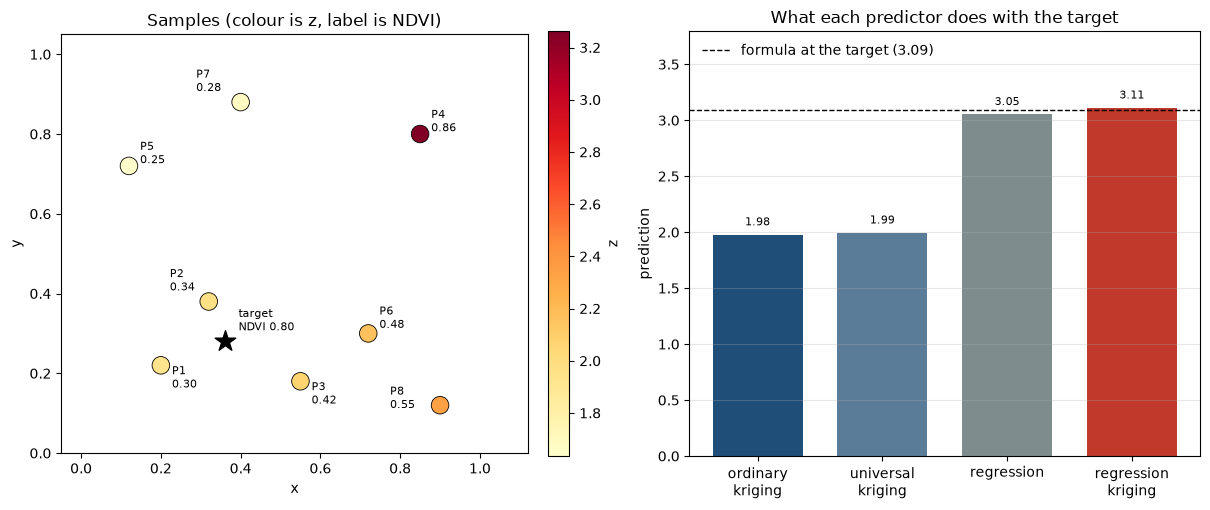

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.2))

ax = axes[0]
sc = ax.scatter(
    samples["x"], samples["y"], c=samples["z"], cmap="YlOrRd",
    s=160, edgecolors="k", linewidths=0.6, zorder=3,
)
offsets = {
    "P1": (8, -16), "P2": (-28, 8), "P3": (8, -16), "P4": (8, 2),
    "P5": (8, 2), "P6": (8, 4), "P7": (-32, 8), "P8": (-36, -2),
}
for _, row in samples.iterrows():
    ax.annotate(
        f"{row['point']}\n{row['ndvi']:.2f}",
        (row["x"], row["y"]),
        textcoords="offset points", xytext=offsets[row["point"]], fontsize=8,
    )
ax.scatter(target[0, 0], target[0, 1], marker="*", s=240, c="k", zorder=4)
ax.annotate(
    "target\nNDVI 0.80",
    (target[0, 0], target[0, 1]),
    textcoords="offset points", xytext=(10, 8), fontsize=8,
)
ax.set_xlim(-0.05, 1.12)
ax.set_ylim(0.00, 1.05)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Samples (colour is z, label is NDVI)")
plt.colorbar(sc, ax=ax, label="z", fraction=0.046, pad=0.04)

ax = axes[1]
names = ["ordinary\nkriging", "universal\nkriging", "regression", "regression\nkriging"]
values = [z_ok, z_uk, m_hat, z_rk]
colors = ["#1f4e79", "#5b7c99", "#7f8c8d", "#c0392b"]
bars = ax.bar(names, values, color=colors, width=0.72)
ax.axhline(z_formula, color="k", lw=1.0, ls="--", label=f"formula at the target ({z_formula:.2f})")
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.06, f"{val:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("prediction")
ax.set_title("What each predictor does with the target")
ax.set_ylim(0, max(values + [z_formula]) * 1.22)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


The residual weights fall on the three nearest samples: P2 ($0.421$), P1 ($0.274$), and P3 ($0.243$). Together they carry $0.94$ of the weight. P4, the only sample whose NDVI is near the target's $0.80$, is the farthest point and its weight is $-0.001$. P4 stays out of the residual sum. What lifts the prediction from the neighbouring values near $2$ up to $3.110$ is the regression, evaluated at NDVI $0.80$: intercept $1.035$ plus slope $2.521$ times $0.80$, which is $3.052$.

The kriged residual then adds $0.058$. P1 and P2, the two heaviest weights, both lie above the fitted line (residuals $+0.138$ and $+0.074$), so the local correction is positive. `RegressionKriging.predict` returns that same sum, $3.110$, and the residual standard error $0.071$.

Ordinary kriging of the raw values returns $1.977$. Universal kriging with a linear drift in the coordinates returns $1.994$. Both stay with the neighbours, because both see $(x, y)$ and neither sees NDVI $0.80$. Their standard errors, about $0.26$, are the kriging standard error of a field that still contains the NDVI trend. After the trend is removed, the residual standard error is $0.071$.

The expression that built the column, evaluated at the target, is $3.094$. Regression kriging lands on $3.110$. The regression alone lands on $3.052$. The residual step is the smaller of the two corrections, which is what a successful covariate fit looks like: most of the map is $\hat m$, and $\hat e$ is a local adjustment with a small sill.


---

## Where the next notebooks go

The call above is the whole estimator: fit a trend on `(X, y)`, krige the residuals at `coords`, add the two surfaces at `(X_new, coords_new)`. What it leaves out is a real covariate set, a held-out test, and a trend that is more than a straight line.

| Next notebook | What it adds to the call you just ran |
|---|---|
| [scikit-learn](05_03_01_regression_kriging_scikit_learn.ipynb) | Every shortcut in `AVAILABLE_REGRESSORS`, 5-fold cross-validation, a held-out test, feature importance, quantile crossing, and a Great Plains prediction grid |
| [H2O](05_03_02_regression_kriging_h2o.ipynb) | `RegressionKrigingH2O`: AutoML and the named H2O estimators, with categorical land cover passed as a factor |
| [PyTorch](05_03_03_regression_kriging_pytorch.ipynb) | `DeepRegressionKriging`: a multilayer perceptron as $f(\mathbf{q})$, plus optional Optuna search |
| [TensorFlow](05_03_04_regression_kriging_dnn_tf.ipynb) | `DeepRegressionKrigingTF`: the same network on Keras |
| [Graph networks](05_03_05_regression_kriging_gnn.ipynb) | `GNNRegressionKriging`, `KCN`, and `IGNNK`, where the trend also sees neighbours |

Open the scikit-learn notebook first. The H2O, PyTorch, TensorFlow, and graph notebooks repeat that workflow with a different engine for $\hat m$, and they leave the residual kriging as it is here.


---

## Resources

### Textbooks and reviews

| Reference | What to read it for |
|---|---|
| Odeh, I.O.A., McBratney, A.B. & Chittleborough, D.J. (1995). Further results on prediction of soil properties from terrain attributes: heterotopic cokriging and regression-kriging. *Geoderma* 67, 215-226. | The soil-mapping statement of regression kriging |
| Hengl, T., Heuvelink, G.B.M. & Stein, A. (2004). A generic framework for spatial prediction of soil variables based on regression-kriging. *Geoderma* 120, 75-93. | The stepwise procedure: regression, residual variogram, kriging, sum |
| Hengl, T., Heuvelink, G.B.M. & Rossiter, D.G. (2007). About regression-kriging: from equations to case studies. *Computers & Geosciences* 33, 1301-1315. | Equivalence with kriging with an external drift when the trend is linear and fitted by generalized least squares |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford. | Simple kriging with a varying local mean |
| Webster, R. & Oliver, M.A. (2007). *Geostatistics for Environmental Scientists* (2nd ed.). Wiley. | Environmental covariates and how to read a kriging variance |
| Chilès, J.-P. & Delfiner, P. (2012). *Geostatistics: Modeling Spatial Uncertainty* (2nd ed.). Wiley. | Universal kriging and external drift inside one linear system |

### In this library

| Object | Role |
|---|---|
| `RegressionKriging` | scikit-learn trend + ordinary kriging of residuals |
| `AVAILABLE_REGRESSORS`, `ENSEMBLE_REGRESSORS`, `STATISTICAL_REGRESSORS` | Shortcut names accepted by `regressor=` |
| `GAMRegressor` | pyGAM additive model with a scikit-learn `fit` / `predict` |
| `enforce_quantile_monotonicity` | Sorts separately fitted quantile surfaces so they stay ordered |
| `RegressionKrigingH2O` | The same sum with an H2O trend |
| `DeepRegressionKriging`, `DeepRegressionKrigingTF` | The same sum with a neural-net trend |
| `GNNRegressionKriging`, `KCN`, `IGNNK` | The same sum with a graph-network trend |
| `OrdinaryKriging`, `Variogram` | The residual half of the estimator |
| `predict(..., return_std=True)` | Prediction and residual kriging standard error |
